# F4 · DINOv2-Reg encoder: speed vs forecast quality per resolution policy

Visual summary of the F4 runs (spec `spec/2026-10-16-dinov2-reg-encoder-wrapper`, results note `results.md`).

**Headline: `native` (centre 5:4 crop → 448×560, 32×40 tokens) encodes about 2.1× faster than `stretch`/`crop`
(448×896, 32×64 tokens), and costs only 0.5–2 % in 1-step forecast quality.** Every policy beats copy-last on every clip.

The notebook only **reads** `throughput.json` and `r5_probe.json` from run dirs under
`$IRWM_OUTPUT_ROOT/feature_extraction/<date>/<time>/` (both runs: hpc-gpu5, NVIDIA L4, commit `4a577ae`).
By default it picks the most recent run of each; set `THROUGHPUT_DIR` / `PROBE_DIR` to pin one.
Setup: `uv sync --group notebook`.

*Forecast ratio* = model SmoothL1 ÷ copy-last SmoothL1 in PCA space, for predicting the next frame (0.167 s) from 4 context frames.
Lower is better; 1.0 = no better than repeating the last frame.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from irwm.utils.paths import load_env, output_root

load_env()

THROUGHPUT_DIR: Path | None = None  # e.g. output_root() / "feature_extraction/2026-10-16/16-16-26"
PROBE_DIR: Path | None = None  # e.g. output_root() / "feature_extraction/2026-10-16/16-16-47"


def latest(name: str) -> Path:
    runs = sorted((output_root() / "feature_extraction").glob(f"*/*/{name}"))
    assert runs, f"no {name} under {output_root() / 'feature_extraction'}"
    return runs[-1].parent


THROUGHPUT_DIR = THROUGHPUT_DIR or latest("throughput.json")
PROBE_DIR = PROBE_DIR or latest("r5_probe.json")
tp = json.loads((THROUGHPUT_DIR / "throughput.json").read_text())
probe = json.loads((PROBE_DIR / "r5_probe.json").read_text())
for name, d, run in [("throughput", tp, THROUGHPUT_DIR), ("r5_probe", probe, PROBE_DIR)]:
    print(f"{name:10s} {run}\n           commit {d['git']['commit'][:7]} dirty={d['git']['dirty']}  gpu {d['gpu']}")

throughput /home/leonardo.ulloa/irwm/outputs/feature_extraction/2026-10-16/16-16-26
           commit 4a577ae dirty=False  gpu NVIDIA L4
r5_probe   /home/leonardo.ulloa/irwm/outputs/feature_extraction/2026-10-16/16-16-47
           commit 4a577ae dirty=False  gpu NVIDIA L4


In [2]:
# Plot style. Color = resolution policy (categorical slots 1-3, fixed order); modality = panel.
POLICIES = ["stretch", "crop", "native"]
MODS = ["rgb", "thermal"]
POLICY_COLOR = {"stretch": "#2a78d6", "crop": "#eb6834", "native": "#1baf7a"}
POLICY_MARKER = {"stretch": "o", "crop": "s", "native": "D"}
POLICY_LABEL = {"stretch": "stretch 448×896", "crop": "crop 448×896", "native": "native 448×560"}
MOD_LABEL = {"rgb": "RGB", "thermal": "Thermal"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
SIZE_OF = {"stretch": [448, 896], "crop": [448, 896], "native": [448, 560]}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def gpu_fps(policy, precision="fp16", batch=16):
    row = next(r for r in tp["gpu_only"]
               if r["size"] == SIZE_OF[policy] and r["precision"] == precision and r["batch_size"] == batch)
    return row["frames_per_s"]


summary = probe["summary"]
split_frames = {r["modality"]: r["split_frames"] for r in tp["end_to_end"]}

## 1. The trade-off

Encoding speed (GPU-only, fp16, batch 16) against the mean forecast ratio over all 330 clips. The thin vertical
line behind each dot spans the 8 per-sequence means (stretch and crop share the same speed and are nudged apart), so the policy differences can be read against how much the
sequences themselves vary. The dashed line at 1.0 is copy-last.

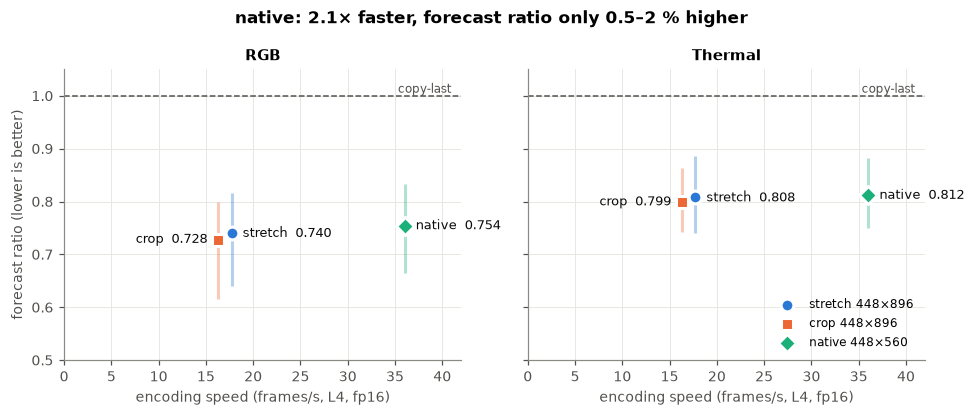

In [3]:
X_NUDGE = {"stretch": 0.7, "crop": -0.7, "native": 0.0}  # stretch and crop run at the same speed; nudged apart to stay visible
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, m in zip(axes, MODS):
    for p in POLICIES:
        s = summary[f"{m}/{p}"]
        x = gpu_fps(p) + X_NUDGE[p]
        seq = list(s["per_sequence_mean_ratio"].values())
        ax.vlines(x, min(seq), max(seq), color=POLICY_COLOR[p], lw=2, alpha=0.35, zorder=2)
        ax.scatter(x, s["mean_ratio"], s=70, marker=POLICY_MARKER[p], color=POLICY_COLOR[p],
                   edgecolor="white", linewidth=2, zorder=3, label=POLICY_LABEL[p])
        dx = 1.2 if p != "crop" else -1.2
        ax.annotate(f"{p}  {s['mean_ratio']:.3f}", (x, s["mean_ratio"]), xytext=(dx * 6, 0),
                    textcoords="offset points", va="center", ha="left" if dx > 0 else "right",
                    color=INK, fontsize=8.5)
    ax.axhline(1.0, color=MUTED, ls="--", lw=1)
    ax.text(41, 1.0, "copy-last", va="bottom", ha="right", color=MUTED, fontsize=8)
    ax.set_title(MOD_LABEL[m])
    ax.set_xlim(0, 42)
    ax.set_xlabel("encoding speed (frames/s, L4, fp16)")
axes[0].set_ylim(0.5, 1.05)
axes[0].set_ylabel("forecast ratio (lower is better)")
axes[1].legend(loc="lower right", fontsize=8)
fig.suptitle("native: 2.1× faster, forecast ratio only 0.5–2 % higher", fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

In [4]:
rows = []
for p in POLICIES:
    fps = gpu_fps(p)
    row = [p, "×".join(map(str, SIZE_OF[p])), f"{fps:.1f}", f"{fps / gpu_fps('stretch'):.2f}×"]
    for m in MODS:
        ratio = summary[f"{m}/{p}"]["mean_ratio"]
        delta = 100 * (ratio / summary[f"{m}/stretch"]["mean_ratio"] - 1)
        row += [f"{split_frames[m] / fps / 60:.1f}", f"{ratio:.3f} ({delta:+.1f} %)"]
    rows.append(row)
table(["policy", "input", "frames/s", "speed vs stretch",
       "RGB min/epoch", "RGB ratio (vs stretch)", "thermal min/epoch", "thermal ratio (vs stretch)"], rows)

| policy | input | frames/s | speed vs stretch | RGB min/epoch | RGB ratio (vs stretch) | thermal min/epoch | thermal ratio (vs stretch) |
|---|---|---|---|---|---|---|---|
| stretch | 448×896 | 17.0 | 1.00× | 10.1 | 0.740 (+0.0 %) | 10.5 | 0.808 (+0.0 %) |
| crop | 448×896 | 17.0 | 1.00× | 10.1 | 0.728 (-1.7 %) | 10.5 | 0.799 (-1.1 %) |
| native | 448×560 | 36.0 | 2.12× | 4.8 | 0.754 (+1.8 %) | 5.0 | 0.812 (+0.5 %) |

Minutes per epoch are the encoding time for one pass over the train split (RGB 10,318 / thermal 10,742 frames)
at the GPU-only rate, before any detector compute. For `stretch` the end-to-end run (real JPEGs, 2 DataLoader
workers) measured the same rate, so data loading kept up. **For `native` the end-to-end rate was not measured**:
at 36 frames/s, 2 workers may become the limit, so give F8 more CPUs or check it.

## 2. Encoding cost per epoch

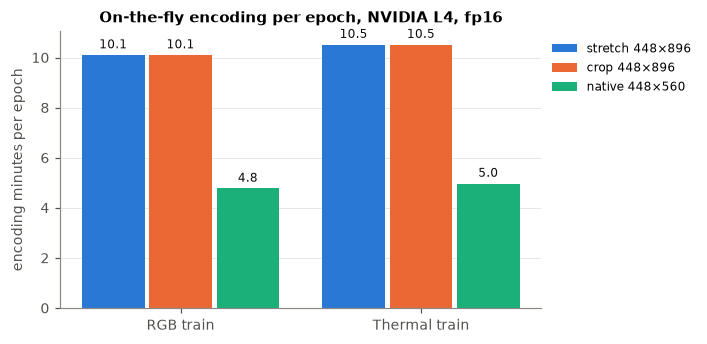

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
w = 0.26
for i, p in enumerate(POLICIES):
    xs = np.arange(len(MODS)) + (i - 1) * (w + 0.02)
    mins = [split_frames[m] / gpu_fps(p) / 60 for m in MODS]
    bars = ax.bar(xs, mins, width=w, color=POLICY_COLOR[p], label=POLICY_LABEL[p])
    for b, v in zip(bars, mins):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.15, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(np.arange(len(MODS)), [f"{MOD_LABEL[m]} train" for m in MODS])
ax.set_ylabel("encoding minutes per epoch")
ax.set_title("On-the-fly encoding per epoch, NVIDIA L4, fp16")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

In [6]:
rows = []
for r in tp["gpu_only"]:
    fps, mem = r["frames_per_s"], r["peak_mem_gb"]
    rows.append(["×".join(map(str, r["size"])), r["precision"], r["batch_size"],
                 fps if fps == "oom" else f"{fps:.1f}", mem if mem == "oom" else f"{mem:.1f}"])
display(Markdown("**All GPU-only measurements** (5 warm-up + 20 timed batches; `oom` = did not fit in the L4's 24 GB)"))
table(["input", "precision", "batch", "frames/s", "peak GB"], rows)

**All GPU-only measurements** (5 warm-up + 20 timed batches; `oom` = did not fit in the L4's 24 GB)

| input | precision | batch | frames/s | peak GB |
|---|---|---|---|---|
| 448×896 | fp16 | 1 | 16.8 | 0.7 |
| 448×896 | fp16 | 16 | 17.0 | 5.7 |
| 448×896 | fp16 | 64 | oom | oom |
| 448×896 | fp32 | 1 | 9.3 | 0.8 |
| 448×896 | fp32 | 16 | 9.3 | 7.3 |
| 448×896 | fp32 | 64 | oom | oom |
| 448×560 | fp16 | 1 | 33.4 | 0.6 |
| 448×560 | fp16 | 16 | 36.0 | 2.6 |
| 448×560 | fp16 | 64 | 36.8 | 9.5 |
| 448×560 | fp32 | 1 | 17.8 | 0.5 |
| 448×560 | fp32 | 16 | 18.9 | 3.3 |
| 448×560 | fp32 | 64 | 18.9 | 12.1 |

- fp16 is about 2× faster than fp32 at every size, so fp16 stays the default.
- Speed is flat from batch 1 to 16: a single frame already saturates the L4. The smaller native grid gains more than
  its 1.6× token ratio because attention cost grows with the square of the token count.
- At 448×896 a batch of 64 does not fit on the L4 in either precision (a failed validation item, kept open by user
  decision: the L4 is the worst-case GPU). Batch 32 works (the end-to-end run used it).

## 3. Forecast quality in detail

Per-sequence mean ratio for each policy (8 test sequences, each a dot row). Clips overlap within a sequence, so
sequences, not clips, are the independent units.

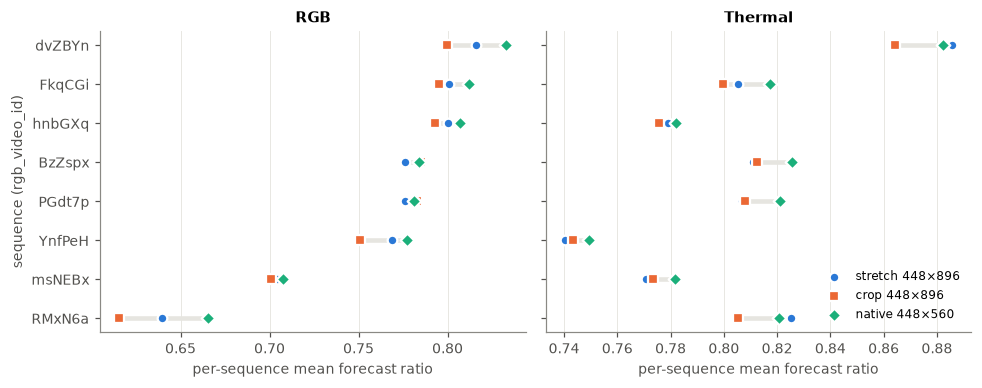

| modality | stretch beats native | crop beats native | crop beats stretch |
|---|---|---|---|
| RGB | 8/8 | 6/8 | 6/8 |
| Thermal | 6/8 | 8/8 | 4/8 |

In [7]:
seqs = list(summary["rgb/stretch"]["per_sequence_mean_ratio"])
order = sorted(seqs, key=lambda k: summary["rgb/stretch"]["per_sequence_mean_ratio"][k])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, m in zip(axes, MODS):
    y = np.arange(len(order))
    vals = {p: [summary[f"{m}/{p}"]["per_sequence_mean_ratio"][k] for k in order] for p in POLICIES}
    ax.hlines(y, np.min(list(vals.values()), axis=0), np.max(list(vals.values()), axis=0), color=GRID, lw=3, zorder=1)
    for p in POLICIES:
        ax.scatter(vals[p], y, s=40, marker=POLICY_MARKER[p], color=POLICY_COLOR[p], edgecolor="white",
                   linewidth=1.5, zorder=3, label=POLICY_LABEL[p])
    ax.set_title(MOD_LABEL[m])
    ax.set_xlabel("per-sequence mean forecast ratio")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(order)), [k[:6] for k in order])
axes[0].set_ylabel("sequence (rgb_video_id)")
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

wins = probe["sequence_wins"]
table(["modality", "stretch beats native", "crop beats native", "crop beats stretch"],
      [[MOD_LABEL[m], f"{wins[m]['stretch<native']}/8", f"{wins[m]['crop<native']}/8", f"{wins[m]['crop<stretch']}/8"]
       for m in MODS])

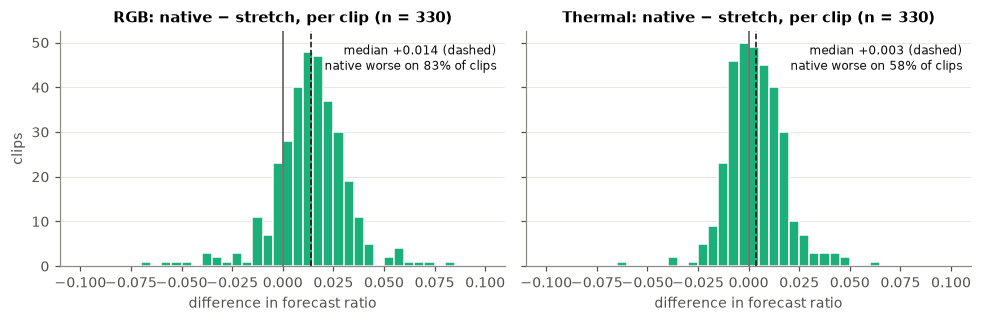

In [8]:
# Paired per-clip difference: native minus stretch (same clip, same frames).
by = {}
for r in probe["rows"]:
    by[(r["modality"], r["policy"], r["clip_id"])] = r["ratio"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, m in zip(axes, MODS):
    d = np.array([by[(m, "native", c)] - by[(m, "stretch", c)]
                  for (mm, p, c) in by if mm == m and p == "stretch"])
    ax.hist(d, bins=np.arange(-0.10, 0.1001, 0.005), color=POLICY_COLOR["native"], edgecolor="white", linewidth=1)
    ax.axvline(0, color=MUTED, lw=1)
    med = float(np.median(d))
    ax.axvline(med, color=INK, lw=1, ls="--")
    ax.text(0.98, 0.95, f"median {med:+.3f} (dashed)\nnative worse on {np.mean(d > 0):.0%} of clips",
            transform=ax.transAxes, va="top", ha="right", fontsize=8, color=INK)
    ax.set_title(f"{MOD_LABEL[m]}: native − stretch, per clip (n = {len(d)})")
    ax.set_xlabel("difference in forecast ratio")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("clips")
fig.tight_layout()
plt.show()

## 4. Encoder equivalence (FR8)

From `pytest -m data tests/test_encoder.py -s` on the same L4 (printed lines, recorded in `results.md`; pytest writes no JSON):

| Test | Comparison | max \|Δ\| |
|---|---|---|
| A | our fp32 encoder vs DINO-Foresight's own extraction, fp32 | **0** (full and PCA) |
| B | our fp16 encoder vs the reference under fp16 autocast | **0** (full and PCA) |
| C | our fp16 vs our fp32 (information only) | 0.405 max, 3.4e-3 mean; mean cosine 0.999995 |

The features used above are bit-identical to the reference's.

## 5. Takeaways

- **`native` is the fast option:** about 2.1× faster encoding (36 vs 17 frames/s on an L4, about 5 vs 10 minutes of
  encoding per epoch per modality), for a forecast ratio 0.5 % (thermal) to 1.9 % (RGB) higher than `stretch`.
  The sequence-to-sequence spread is several times larger than that difference.
- It also keeps the full thermal frame (640×512 is already 5:4) without distortion; RGB loses 4–17 % at the edges.
- `crop` is marginally best on forecasting, but cuts 37.5 % of every thermal frame and is no faster than `stretch`.
- **Caveats:** this is 1-step forecasting in PCA space, not detection (small objects, R3, may prefer more tokens per
  object); native's 32×40 grid is interpolated for both DINOv2-Reg and DINO-Foresight; native's end-to-end speed with
  real data loading is not measured yet.
- **R5 is the user's decision**; this notebook only summarises the evidence.